# MosaicFormer Architecture Implementation

This notebook mirrors the learning style of the GPT architecture notebook. Run it from top to bottom to understand each MosaicFormer component.

In [1]:
import sys
from pathlib import Path

CANDIDATES = [
    Path.cwd(),
    Path.cwd() / 'MosaicFormer',
    Path.cwd().parent,
    Path.cwd().parent / 'MosaicFormer',
    Path.cwd().parent.parent / 'MosaicFormer',
]
PROJECT_DIR = next((path for path in CANDIDATES if (path / 'model.py').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook from the LLM folder or the MosaicFormer folder.')
sys.path.insert(0, str(PROJECT_DIR.resolve()))

import torch
import matplotlib.pyplot as plt

from model import (
    MosaicFormerModel, MosaicTransformerBlock, LocalCausalAttention,
    MemoryCompressor, MemoryCrossAttention, GatedFusion,
    build_local_causal_mask, make_mosaic_config,
)

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## 1. Small configuration

The values are deliberately small so they fit on a 4GB GPU. `context_length` must be divisible by `chunk_size`.

In [2]:
CONFIG = make_mosaic_config(vocab_size=50257)
CONFIG.update({
    'context_length': 256,
    'chunk_size': 64,
    'window_size': 64,
    'num_memory_tokens': 8,
    'max_memory_chunks': 4,
})
CONFIG

{'vocab_size': 50257,
 'context_length': 256,
 'emb_dim': 128,
 'n_heads': 4,
 'n_layers': 4,
 'dropout': 0.1,
 'qkv_bias': False,
 'chunk_size': 64,
 'window_size': 64,
 'num_memory_tokens': 8,
 'max_memory_chunks': 4,
 'use_memory': True,
 'use_gate': True}

## 2. Local causal attention

Each token sees only previous tokens in its local window. This is the short-term, exact-detail path.

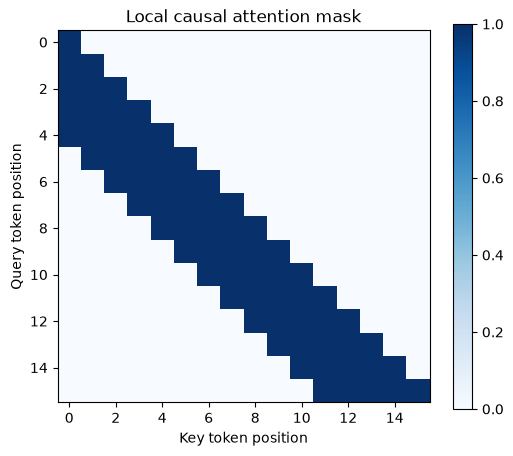

In [3]:
mask = build_local_causal_mask(num_tokens=16, window_size=5, device=device)
plt.figure(figsize=(6, 5))
plt.imshow(mask.cpu(), cmap='Blues')
plt.xlabel('Key token position')
plt.ylabel('Query token position')
plt.title('Local causal attention mask')
plt.colorbar()
plt.show()

In [4]:
x = torch.randn(2, 64, CONFIG['emb_dim']).to(device)
local_attention = LocalCausalAttention(CONFIG).to(device)
local_output = local_attention(x)
print('Input shape:', x.shape)
print('Local attention output:', local_output.shape)

Input shape: torch.Size([2, 64, 128])
Local attention output: torch.Size([2, 64, 128])


## 3. Learned memory compression

Formula: `M = softmax(PK^T / sqrt(d))V`.

`P` is a small learnable query matrix. Each query learns a different soft summary of the chunk.

In [6]:
compressor = MemoryCompressor(CONFIG).to(device)
memory = compressor(x)
print('Chunk states:', x.shape)
print('Compressed memory:', memory.shape)
print('Compression ratio:', x.shape[1] / memory.shape[1])

Chunk states: torch.Size([2, 64, 128])
Compressed memory: torch.Size([2, 8, 128])
Compression ratio: 8.0


## 4. Memory retrieval and gated fusion

Current tokens query historical memory. The gate chooses the blend: `H_out = G * H_local + (1 - G) * H_memory`.

In [8]:
old_memory = torch.randn(2, 24, CONFIG['emb_dim']).to(device)
memory_attention = MemoryCrossAttention(CONFIG).to(device)
fusion = GatedFusion(CONFIG).to(device)

memory_output = memory_attention(x, old_memory)
fused_output = fusion(local_output, memory_output)
print('Retrieved memory:', memory_output.shape)
print('Fused output:', fused_output.shape)

Retrieved memory: torch.Size([2, 64, 128])
Fused output: torch.Size([2, 64, 128])


## 5. One MosaicFormer block

The block keeps the familiar Transformer pattern: LayerNorm, attention, residual connection, feedforward, residual connection.

In [10]:
block = MosaicTransformerBlock(CONFIG).to(device)
block_output, new_memory = block(x, old_memory)
print('Block output:', block_output.shape)
print('New memory:', new_memory.shape)

Block output: torch.Size([2, 64, 128])
New memory: torch.Size([2, 8, 128])


## 6. Full language model shape test

The model splits a full sequence into chunks and keeps one memory bank per layer.

In [11]:
model = MosaicFormerModel(CONFIG).to(device)
input_ids = torch.randint(0, CONFIG['vocab_size'], (2, CONFIG['context_length'])).to(device)
logits = model(input_ids)
print('Input IDs:', input_ids.shape)
print('Logits:', logits.shape)
print(f'Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M')

Input IDs: torch.Size([2, 256])
Logits: torch.Size([2, 256, 50257])
Parameters: 14.22M


## What to understand before moving on

- Local attention preserves nearby token detail.
- The memory compressor converts 64 states into 8 learned vectors.
- Cross-attention retrieves older information without looking at every old token.
- The gate lets the model ignore memory when local context is enough.

Open `MosaicFormer_Pretraining_and_Experiments.ipynb` next.